# Praktikum 5 - Sequential Pattern Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("data.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
print('Ukuran awal:', df.shape)
df.info()

ringkasan_sebelum = {
    'Baris': len(df),
    'Invoice': df['InvoiceNo'].nunique(),
    'Pelanggan': df['CustomerID'].nunique(dropna=True),
}
pd.Series(ringkasan_sebelum, name='Sebelum pembersihan')

Ukuran awal: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


Baris        541909
Invoice       25900
Pelanggan      4372
Name: Sebelum pembersihan, dtype: int64

In [3]:
mask_invoice_batal = df['InvoiceNo'].astype(str).str.startswith('C', na=False)
df = df.loc[
    df['Description'].notna()
    & df['CustomerID'].notna()
    & ~mask_invoice_batal
    & df['Quantity'].gt(0)
].copy()

ringkasan_setelah = {
    'Baris': len(df),
    'Invoice': df['InvoiceNo'].nunique(),
    'Pelanggan': df['CustomerID'].nunique(),
}
pd.DataFrame(
    [ringkasan_sebelum, ringkasan_setelah],
    index=['Sebelum pembersihan', 'Sesudah pembersihan dasar']
)

,Baris,Invoice,Pelanggan
Sebelum pembersihan,541909,25900,4372
Sesudah pembersihan dasar,397924,18536,4339


In [4]:
basket = pd.crosstab(
    index=df['InvoiceNo'],
    columns=df['Description']
).gt(0)

basket.head()

Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,I LOVE LONDON MINI RUCKSACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [5]:
kata = r'return|test|wrongly|adjust|coded'

df.loc[
    df['Description'].str.contains(kata, case=False, na=False),
    ['InvoiceNo', 'StockCode', 'Description', 'Quantity']
].head(20)

,InvoiceNo,StockCode,Description,Quantity


In [6]:
df.loc[
    df['Description'].str.contains(kata, case=False, na=False),
    'Description'
].value_counts()

Series([], Name: count, dtype: int64)

In [ ]:
deskripsi_bukan_produk = {
    'postage',
    'dotcom postage',
    'carriage',
    'next day carriage',
    'manual',
    'check',
    'check?',
    'found',
    'found by jackie',
    'found in w/hse',
    'found box',
    'adjustment',
    'adjust bad debt',
    'test',
    'returned',
    'taig adjust',
    'bank charges',
    'amazon fee',
    'amazon',
    'amazon adjustment',
    'amazon adjust',
    'amazon sales',
    'dotcom',
    'dotcom adjust',
    'dotcomstock',
    'had been put aside',
    'had been put aside.',
    'high resolution image',
    'mailout',
    'samples',
    'lighthouse trading zero invc incorr',
    'marked as 23343',
    'sale error',
    'allocate stock for dotcom orders ta',
    'came coded as 20713',
    'damaged',
    'did a credit and did not tick ret',
    'for online retail orders',
    'incorrectly credited c550456 see 47',
    'michel oops',
    'on cargo order',
    'rcvd be air temp fix for dotcom sit',
    'wrongly sold (22719) barcode',
    'wrongly coded 20713',
    'wrongly coded 23343',
    'wrongly marked',
    'wrongly marked 23343',
    'to push order througha s stock was',
    'website fixed',
}

kode_bukan_produk = {
    'POST', 'DOT', 'C2', '23444', 'M',
    'BANK CHARGES', 'AMAZONFEE', 'S', 'B'
}

deskripsi_normal = (
    df['Description']
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .str.casefold()
)
kode_normal = df['StockCode'].astype(str).str.strip().str.upper()
mask_bukan_produk = (
    deskripsi_normal.isin(deskripsi_bukan_produk)
    | kode_normal.isin(kode_bukan_produk)
)


print(df.loc[mask_bukan_produk, 'Description'].value_counts().to_string())
jumlah_dihapus = int(mask_bukan_produk.sum())
df = df.loc[~mask_bukan_produk].copy()

print(f'Baris non-produk yang dihapus: {jumlah_dihapus}')

basket = pd.crosstab(
    index=df['InvoiceNo'],
    columns=df['Description']
).gt(0)

print('Ukuran basket:', basket.shape)
basket.head()

Rincian baris nonproduk yang akan dihapus:
Description
POSTAGE                  1099
Manual                    290
CARRIAGE                  133
Next Day Carriage          79
DOTCOM POSTAGE             16
Bank Charges               12
High Resolution Image       3
Baris non-produk yang dihapus: 1632


Ukuran basket: (18402, 3870)


Description,4 PURPLE FLOCK DINNER CANDLES,50'S CHRISTMAS GIFT BAG LARGE,DOLLY GIRL BEAKER,I LOVE LONDON MINI BACKPACK,I LOVE LONDON MINI RUCKSACK,NINE DRAWER OFFICE TIDY,OVAL WALL MIRROR DIAMANTE,RED SPOT GIFT BAG LARGE,SET 2 TEA TOWELS I LOVE LONDON,SPACEBOY BABY GIFT SET,...,ZINC STAR T-LIGHT HOLDER,ZINC SWEETHEART SOAP DISH,ZINC SWEETHEART WIRE LETTER RACK,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC TOP 2 DOOR WOODEN SHELF,ZINC WILLIE WINKIE CANDLE STICK,ZINC WIRE KITCHEN ORGANISER,ZINC WIRE SWEETHEART LETTER TRAY
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
mask_sisa_nonproduk = (
    df['Description']
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .str.casefold()
    .isin(deskripsi_bukan_produk)
    | df['StockCode'].astype(str).str.strip().str.upper().isin(kode_bukan_produk)
)


Kandidat nonproduk yang masih tersisa: 0


,StockCode,Description


In [9]:
df_seq = df.copy()
df_seq['_item'] = (
    df_seq['Description']
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .str.casefold()
)

urutan_invoice = df_seq.sort_values(
    ['CustomerID', 'InvoiceDate', 'InvoiceNo', 'StockCode'],
    kind='mergesort'
)
invoice_itemsets = (
    urutan_invoice
    .groupby(['CustomerID', 'InvoiceNo'], sort=False, as_index=False)
    .agg(
        InvoiceDate=('InvoiceDate', 'min'),
        Items=('_item', lambda items: sorted(set(items)))
    )
    .sort_values(['CustomerID', 'InvoiceDate', 'InvoiceNo'], kind='mergesort')
)

customer_ids = []
customer_sequences = []
for customer_id, transaksi in invoice_itemsets.groupby('CustomerID', sort=False):
    customer_ids.append(customer_id)
    customer_sequences.append(transaksi['Items'].tolist())

label_item = (
    df_seq.groupby('_item')['Description']
    .agg(lambda labels: labels.value_counts().index[0])
    .to_dict()
)

ringkasan_final = pd.DataFrame(
    [ringkasan_sebelum, ringkasan_setelah, {
        'Baris': len(df),
        'Invoice': df['InvoiceNo'].nunique(),
        'Pelanggan': df['CustomerID'].nunique(),
    }],
    index=['Data awal', 'Sesudah pembersihan dasar', 'Sesudah menghapus kandidat nonproduk']
)
display(ringkasan_final)
print(f'Jumlah sequence pelanggan: {len(customer_sequences):,}')
print(f'Jumlah itemset invoice: {len(invoice_itemsets):,}')
print('Contoh sequence pelanggan pertama:', customer_sequences[0][:3])

,Baris,Invoice,Pelanggan
Data awal,541909,25900,4372
Sesudah pembersihan dasar,397924,18536,4339
Sesudah menghapus kandidat nonproduk,396292,18402,4335


Jumlah sequence pelanggan: 4,335
Jumlah itemset invoice: 18,402
Contoh sequence pelanggan pertama: [['medium ceramic top storage jar']]


In [10]:
from collections import defaultdict
from math import ceil

minimum_support = 0.01
minimum_support_count = ceil(minimum_support * len(customer_sequences))
maximum_pattern_length = 2
support_counts = {}

def prefixspan_extend(prefix, projected_database):
    extensions = defaultdict(lambda: defaultdict(set))

    for customer_index, occurrences in projected_database.items():
        sequence = customer_sequences[customer_index]
        for position, last_item in occurrences:
            for item in sequence[position]:
                if item > last_item:
                    extensions[('I', item)][customer_index].add((position, item))
            for later_position in range(position + 1, len(sequence)):
                for item in sequence[later_position]:
                    extensions[('S', item)][customer_index].add((later_position, item))

    for (extension_type, item), projection in sorted(extensions.items()):
        support_count = len(projection)
        if support_count < minimum_support_count:
            continue

        if extension_type == 'I':
            next_prefix = prefix[:-1] + (prefix[-1] + (item,),)
        else:
            next_prefix = prefix + ((item,),)
        support_counts[next_prefix] = support_count

        pattern_length = sum(len(itemset) for itemset in next_prefix)
        if pattern_length < maximum_pattern_length:
            prefixspan_extend(next_prefix, projection)

initial_projections = defaultdict(lambda: defaultdict(set))
for customer_index, sequence in enumerate(customer_sequences):
    for position, itemset in enumerate(sequence):
        for item in itemset:
            initial_projections[item][customer_index].add((position, item))

for item, projection in sorted(initial_projections.items()):
    support_count = len(projection)
    if support_count >= minimum_support_count:
        prefix = ((item,),)
        support_counts[prefix] = support_count
        if maximum_pattern_length > 1:
            prefixspan_extend(prefix, projection)

print(f'Minimum support: {minimum_support:.0%} ({minimum_support_count} pelanggan)')
print(f'Panjang pola maksimum: {maximum_pattern_length} item')
print(f'Jumlah pola frequent yang ditemukan: {len(support_counts):,}')

Minimum support: 1% (44 pelanggan)
Panjang pola maksimum: 2 item
Jumlah pola frequent yang ditemukan: 22,813


Total pola sequential (panjang >= 2): 15,686


,Pola berurutan,Jumlah pelanggan,Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HA...,405,0.093426,0.473131
1,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND ...,330,0.076125,0.374574
2,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETRO...,312,0.071972,0.491339
3,ASSORTED COLOUR BIRD ORNAMENT -> ASSORTED COLO...,291,0.067128,0.429204
4,PARTY BUNTING -> PARTY BUNTING,280,0.064591,0.395480
5,LUNCH BAG RED RETROSPOT -> LUNCH BAG RED RETRO...,276,0.063668,0.518797
6,LUNCH BAG BLACK SKULL. -> LUNCH BAG BLACK SK...,229,0.052826,0.500000
7,LUNCH BAG SUKI DESIGN -> LUNCH BAG SUKI DESIGN,226,0.052134,0.520737
8,SET OF 3 CAKE TINS PANTRY DESIGN -> SET OF 3 ...,225,0.051903,0.351562
9,LUNCH BAG RED RETROSPOT -> LUNCH BAG BLACK SK...,212,0.048904,0.398496


Tiga pola dengan support tertinggi:


,Pola berurutan,Jumlah pelanggan,Support,Confidence,Interpretasi bisnis
0,WHITE HANGING HEART T-LIGHT HOLDER -> WHITE HA...,405,0.093426,0.473131,Pola ini muncul pada 405 pelanggan (support 9....
1,REGENCY CAKESTAND 3 TIER -> REGENCY CAKESTAND ...,330,0.076125,0.374574,Pola ini muncul pada 330 pelanggan (support 7....
2,JUMBO BAG RED RETROSPOT -> JUMBO BAG RED RETRO...,312,0.071972,0.491339,Pola ini muncul pada 312 pelanggan (support 7....


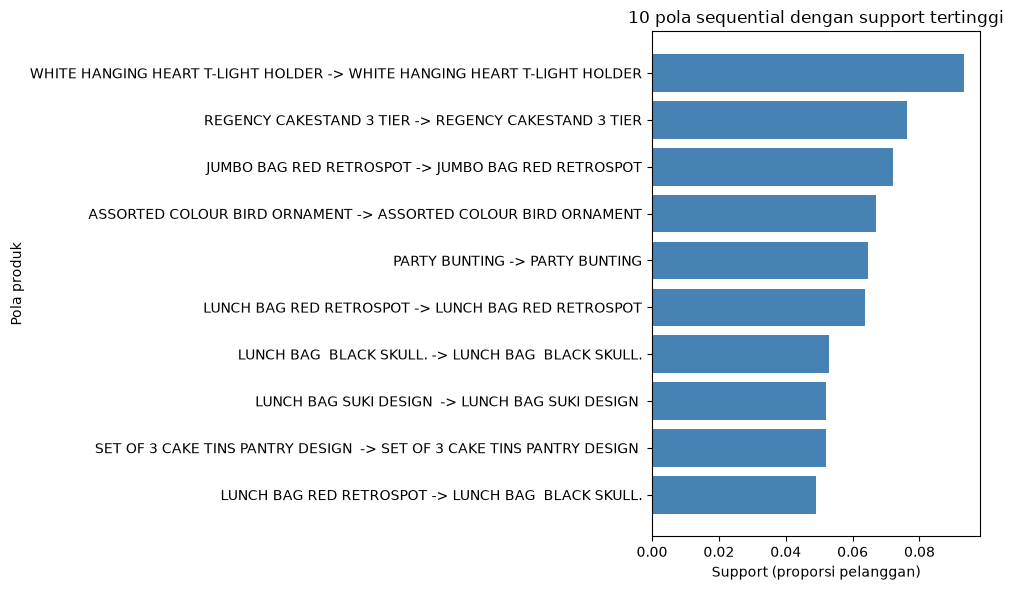

In [11]:
def format_pattern(pattern):
    return ' -> '.join(
        ' + '.join(label_item[item] for item in itemset)
        for itemset in pattern
    )

hasil_pola = []
jumlah_pelanggan = len(customer_sequences)
for pattern, support_count in support_counts.items():
    if len(pattern) < 2:
        continue
    if len(pattern[-1]) > 1:
        prefix = pattern[:-1] + (pattern[-1][:-1],)
    else:
        prefix = pattern[:-1]
    confidence = support_count / support_counts[prefix]
    hasil_pola.append({
        'Pola berurutan': format_pattern(pattern),
        'Pola internal': pattern,
        'Jumlah pelanggan': support_count,
        'Support': support_count / jumlah_pelanggan,
        'Confidence': confidence,
    })

hasil_pola = pd.DataFrame(hasil_pola)
if hasil_pola.empty:
    raise ValueError('Tidak ada pola dengan panjang minimal dua pada minimum support yang dipilih.')

hasil_pola = hasil_pola.sort_values(
    ['Support', 'Confidence', 'Jumlah pelanggan'],
    ascending=False
).reset_index(drop=True)
print(f'Total pola sequential (panjang >= 2): {len(hasil_pola):,}')
display(hasil_pola.drop(columns='Pola internal').head(20))

top3 = hasil_pola.head(3)
print('Tiga pola dengan support tertinggi:')
display(top3[['Pola berurutan', 'Jumlah pelanggan', 'Support', 'Confidence']])

plot_data = hasil_pola.head(10).sort_values('Support')
plt.figure(figsize=(10, 6))
plt.barh(plot_data['Pola berurutan'], plot_data['Support'], color='steelblue')
plt.xlabel('Support (proporsi pelanggan)')
plt.ylabel('Pola produk')
plt.title('10 pola sequential dengan support tertinggi')
plt.tight_layout()
plt.show()

### Interpretasi tiga pola teratas

Tiga pola teratas menunjukkan pelanggan yang membeli produk yang sama lagi pada invoice berikutnya. Pola ini dapat menjadi masukan untuk rekomendasi atau kampanye pembelian ulang. Confidence menunjukkan proporsi pelanggan pada pola awal yang kemudian mengikuti pola lengkap; hasil ini menunjukkan keterkaitan, bukan sebab-akibat.